# Transformada de Hough

**Procesamiento de Imágenes — Universidad Diego Portales**

En la clase de bordes terminamos con Canny: un mapa de **píxeles sueltos**. Un computador todavía no
sabe que esos píxeles forman una recta o una moneda. La transformada de Hough da ese paso con una idea
simple: **cada píxel de borde vota por todas las formas que podrían pasar por él**, y las formas que
reciben muchos votos son las que existen en la imagen.

Todo el desarrollo se hace con la recta:

$$\rho = x\cos\theta + y\sin\theta$$

Contenido:

1. Motivación: de bordes a formas
2. La idea: el espacio de parámetros $(m, b)$
3. La forma normal $(\rho, \theta)$
4. El acumulador, programado a mano
5. Ejercicios a mano: comprueba tus cálculos
6. Transición: de nuestro código a OpenCV
7. Aplicación con OpenCV: rectas en una carretera
8. Extensiones: círculos, elipses y formas arbitrarias
9. Un adelanto: RANSAC
10. Actividad final

Las secciones **Explora** están pensadas para que cambies parámetros, imágenes o agregues código.

## 0. Preparación

In [1]:
import os
import sys
import time

import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage
from skimage import data
from skimage.draw import ellipse_perimeter
from skimage.measure import LineModelND, ransac
from skimage.transform import hough_ellipse
import ipywidgets as widgets
from ipywidgets import interact

plt.rcParams.update({"image.cmap": "gray", "axes.titlesize": 13, "font.size": 12})

# ---- Parámetros generales ----
CARPETA_IMAGENES = "imagenes"   # imágenes especiales de la clase
RUTA_ARCHIVO = None             # p. ej. "mi_foto.jpg" para usar una imagen propia

**Solo en Google Colab:** la celda siguiente pide subir las imágenes de la carpeta `imagenes`
(los archivos que acompañan este cuaderno). Si trabajas en tu computador, no hace nada.

In [2]:
EN_COLAB = "google.colab" in sys.modules
if EN_COLAB and not os.path.isdir(CARPETA_IMAGENES):
    from google.colab import files
    os.makedirs(CARPETA_IMAGENES, exist_ok=True)
    for nombre, contenido in files.upload().items():
        with open(os.path.join(CARPETA_IMAGENES, nombre), "wb") as archivo:
            archivo.write(contenido)

### 0.1 Imágenes y utilidades

`cargar(nombre)` acepta `"coins"` o `"camera"` (de `skimage.data`), un archivo de la carpeta `imagenes`
o una ruta propia. Siempre devuelve una imagen en gris, `uint8`, porque es lo que pide OpenCV.

In [3]:
IMAGENES_SKIMAGE = {"coins": data.coins, "camera": data.camera}


def cargar(nombre):
    if nombre in IMAGENES_SKIMAGE:
        return IMAGENES_SKIMAGE[nombre]()
    ruta = os.path.join(CARPETA_IMAGENES, nombre)
    return cv2.imread(ruta if os.path.exists(ruta) else nombre, cv2.IMREAD_GRAYSCALE)


def cargar_color(nombre):
    ruta = os.path.join(CARPETA_IMAGENES, nombre)
    return cv2.cvtColor(cv2.imread(ruta if os.path.exists(ruta) else nombre), cv2.COLOR_BGR2RGB)


def opciones_imagenes():
    # Lista para los menús de los controles interactivos
    nombres = list(IMAGENES_SKIMAGE)
    if os.path.isdir(CARPETA_IMAGENES):
        nombres += sorted(n for n in os.listdir(CARPETA_IMAGENES) if n.lower().endswith((".png", ".jpg", ".jpeg")))
    if RUTA_ARCHIVO:
        nombres = [RUTA_ARCHIVO] + nombres
    return nombres


def ver(imagenes, titulos, cmaps=None, figsize=None):
    # Muestra una fila de imágenes
    n = len(imagenes)
    fig, ax = plt.subplots(1, n, figsize=figsize or (4.6 * n, 4), squeeze=False)
    for k, (a, im, t) in enumerate(zip(ax[0], imagenes, titulos)):
        a.imshow(im, cmap=(cmaps[k] if cmaps else "gray"))
        a.set_title(t)
        a.axis("off")
    fig.tight_layout()
    plt.show()


print(opciones_imagenes())

['coins', 'camera', 'camara_burbujas.jpg', 'carretera.jpg', 'documento_inclinado.png', 'flotacion.jpg', 'formas_bordes.png', 'gotas_simuladas.png', 'iris.jpg', 'sangre.jpg']


---
## 1. Motivación: de bordes a formas

Canny encuentra **dónde** hay un borde, pero no **qué forma** tiene. Los píxeles vienen cortados, con
ruido y sin ninguna agrupación.

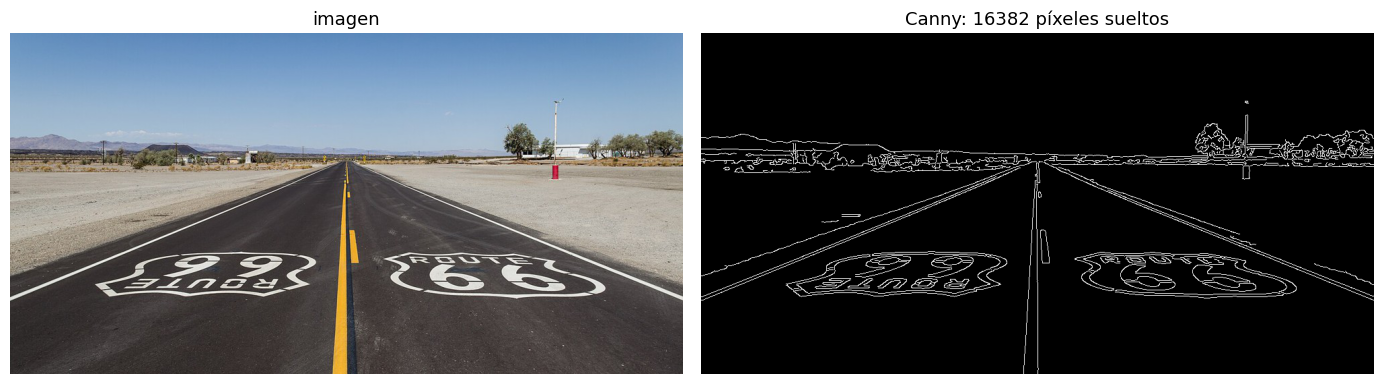

In [4]:
carretera = cargar_color("carretera.jpg")
gris = cv2.cvtColor(carretera, cv2.COLOR_RGB2GRAY)
bordes = cv2.Canny(cv2.GaussianBlur(gris, (5, 5), 1.2), 70, 180)
ver([carretera, bordes], ["imagen", f"Canny: {np.count_nonzero(bordes)} píxeles sueltos"], figsize=(14, 4))

Encontrar rectas sirve también para **segmentar**: separar una imagen en regiones usando sus
discontinuidades. Con los círculos de las monedas, por ejemplo, obtenemos directamente una máscara de
los objetos. Ese resultado es el que armaremos en la sección 8.

### 1.1 ¿Por qué no basta con ajustar una recta?

Mínimos cuadrados necesita saber **qué puntos pertenecen a la recta**, y eso es justo lo que no sabemos.

Recta real:          y = 0.60 x + 1.00
Mínimos cuadrados:   y = 0.47 x + 1.12


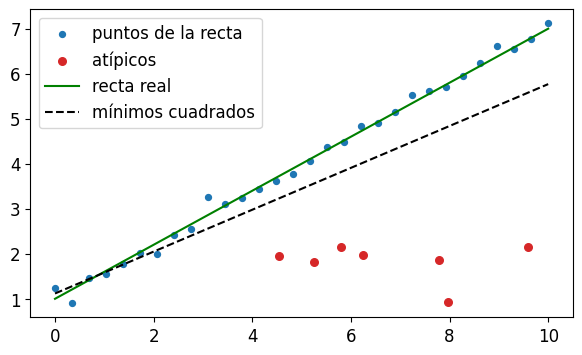

In [5]:
rng = np.random.default_rng(3)
x = np.linspace(0, 10, 30)
y = 0.6 * x + 1 + rng.normal(0, 0.12, 30)
x_atip, y_atip = rng.uniform(4, 10, 7), rng.uniform(0.5, 2.5, 7)

m_todos, b_todos = np.polyfit(np.r_[x, x_atip], np.r_[y, y_atip], 1)
print(f"Recta real:          y = 0.60 x + 1.00")
print(f"Mínimos cuadrados:   y = {m_todos:.2f} x + {b_todos:.2f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(x, y, s=18, label="puntos de la recta")
ax.scatter(x_atip, y_atip, color="tab:red", s=30, label="atípicos")
xx = np.array([0, 10])
ax.plot(xx, 0.6 * xx + 1, "g", label="recta real")
ax.plot(xx, m_todos * xx + b_todos, "k--", label="mínimos cuadrados")
ax.legend()
plt.show()

Otra opción sería probar la recta que pasa por **cada par** de puntos, pero con $n$ puntos son
$n(n-1)/2$ rectas. Con 5 000 píxeles de borde son unos 12.5 millones de rectas, y a cada una habría que
contarle sus puntos. Hough evita esto.

---
## 2. La idea: el espacio de parámetros $(m, b)$

Una recta es $y = mx + b$. Si **fijamos** un punto $(x_i, y_i)$ y dejamos libres $m$ y $b$, obtenemos

$$b = y_i - x_i\, m$$

que es **una recta en el plano $(m, b)$**: todas las rectas que pasan por ese punto.

| Espacio de la imagen $(x, y)$ | Espacio de parámetros $(m, b)$ |
|---|---|
| un punto | una recta |
| una recta | un punto |
| varios puntos alineados | varias rectas que se cruzan en un punto |

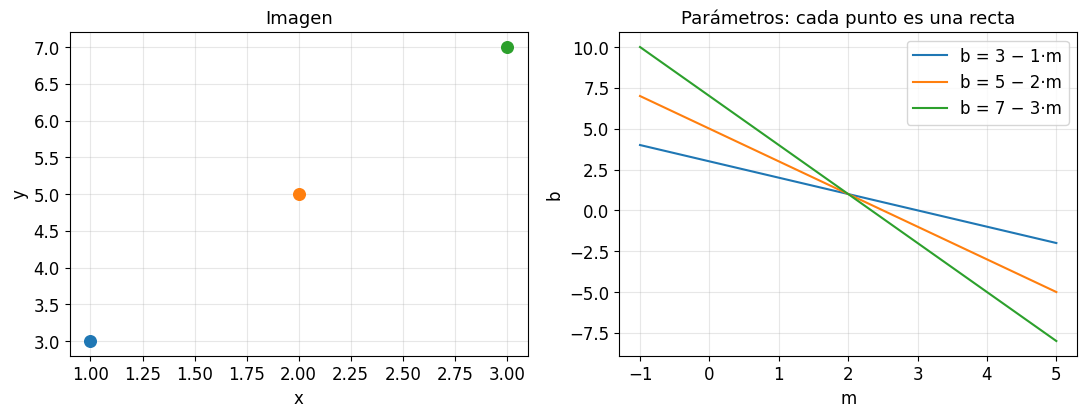

In [6]:
puntos = [(1, 3), (2, 5), (3, 7)]   # prueba moviendo uno de estos puntos

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for x_i, y_i in puntos:
    ax[0].scatter(x_i, y_i, s=70, zorder=3)
    mm = np.linspace(-1, 5, 10)
    ax[1].plot(mm, y_i - x_i * mm, label=f"b = {y_i} − {x_i}·m")
ax[0].set_title("Imagen")
ax[0].set_xlabel("x")
ax[0].set_ylabel("y")
ax[1].set_title("Parámetros: cada punto es una recta")
ax[1].set_xlabel("m")
ax[1].set_ylabel("b")
ax[1].legend()
for a in ax:
    a.grid(alpha=0.3)
plt.show()

**El problema:** una recta vertical tiene $m \to \infty$. Además, $m$ y $b$ no tienen límites, así que no
se pueden guardar en una matriz de tamaño finito. Necesitamos otra forma de escribir la recta.

---
## 3. La forma normal $(\rho, \theta)$

Describimos la recta por su **perpendicular desde el origen**: $\rho$ es la distancia con signo y
$\theta$ es el ángulo de esa perpendicular.

$$\rho = x\cos\theta + y\sin\theta$$

**Convención de esta clase (la misma de OpenCV):**

- Origen arriba a la izquierda, $x$ = columna, $y$ = fila (crece hacia **abajo**).
- $\theta \in [0°, 180°)$ y $\rho \in [-D, D]$, con $D = \sqrt{M^2 + N^2}$, la diagonal de la imagen.
- Recta vertical: $\theta = 0°$. Recta horizontal: $\theta = 90°$.

Ambos parámetros están **acotados**: ya podemos guardarlos en una matriz. A cambio, un punto de la imagen
ya no es una recta sino una **sinusoide**.

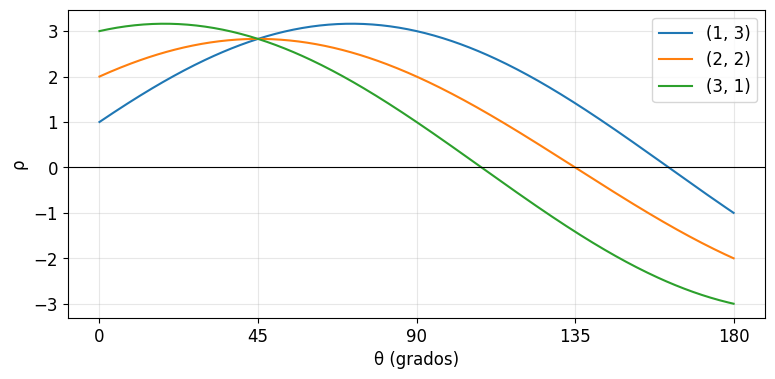

Los tres puntos dan el mismo ρ en θ = 45°: [2.8284, 2.8284, 2.8284]


In [7]:
def rho_de(x, y, theta_grados):
    t = np.deg2rad(theta_grados)
    return x * np.cos(t) + y * np.sin(t)


theta = np.linspace(0, 180, 361)
puntos = [(1, 3), (2, 2), (3, 1)]

fig, ax = plt.subplots(figsize=(9, 4))
for x_i, y_i in puntos:
    ax.plot(theta, rho_de(x_i, y_i, theta), label=f"({x_i}, {y_i})")
ax.axhline(0, color="k", lw=0.8)
ax.set_xlabel("θ (grados)")
ax.set_ylabel("ρ")
ax.set_xticks(range(0, 181, 45))
ax.legend()
ax.grid(alpha=0.3)
plt.show()

print("Los tres puntos dan el mismo ρ en θ = 45°:", [round(rho_de(x_i, y_i, 45), 4) for x_i, y_i in puntos])

### 3.1 Explora: puntos y sinusoides

Mueve los puntos. Cuando los tres están alineados, sus sinusoides se cruzan en **un solo punto**, y ese
punto da los parámetros de la recta.

In [8]:
def _deslizador(valor, nombre):
    return widgets.FloatSlider(value=valor, min=0, max=10, step=0.5, description=nombre, continuous_update=False)


@interact(x1=_deslizador(1, "x1"), y1=_deslizador(3, "y1"),
          x2=_deslizador(2, "x2"), y2=_deslizador(2, "y2"),
          x3=_deslizador(3, "x3"), y3=_deslizador(1, "y3"))
def explorar_sinusoides(x1, y1, x2, y2, x3, y3):
    puntos = [(x1, y1), (x2, y2), (x3, y3)]
    colores = ["tab:blue", "tab:orange", "tab:purple"]
    theta = np.linspace(0, 180, 721)
    fig, ax = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [1, 2]})
    for (x_i, y_i), c in zip(puntos, colores):
        ax[0].scatter(x_i, y_i, color=c, s=70)
        ax[1].plot(theta, rho_de(x_i, y_i, theta), color=c, label=f"({x_i}, {y_i})")
    ax[0].set_xlim(-0.5, 10.5)
    ax[0].set_ylim(10.5, -0.5)
    ax[0].set_aspect("equal")
    ax[0].set_xlabel("x")
    ax[0].set_ylabel("y")
    ax[0].grid(alpha=0.3)
    ax[1].axhline(0, color="k", lw=0.8)
    ax[1].set_xticks(range(0, 181, 45))
    ax[1].set_xlabel("θ (grados)")
    ax[1].set_ylabel("ρ")
    ax[1].legend()
    ax[1].grid(alpha=0.3)
    plt.show()

interactive(children=(FloatSlider(value=1.0, continuous_update=False, description='x1', max=10.0, step=0.5), F…

---
## 4. El acumulador, programado a mano

Los puntos reales no se cruzan exactamente, así que **discretizamos**: una matriz $A(\rho, \theta)$ donde
cada celda cuenta votos.

1. Crear $A$ en cero, con los pasos $\Delta\rho$ y $\Delta\theta$.
2. Para cada píxel de borde $(x, y)$ y cada $\theta$: calcular $\rho = x\cos\theta + y\sin\theta$,
   redondearlo a su celda y sumar un voto.
3. Las celdas con muchos votos son las rectas.

### 4.1 La versión más directa: dos bucles

In [9]:
def hough_con_bucles(bordes, dtheta=1.0, drho=1.0):
    M, N = bordes.shape
    D = int(np.ceil(np.hypot(M, N)))             # la diagonal: el mayor |ρ| posible
    thetas = np.arange(0, 180, dtheta)
    rhos = np.arange(-D, D + drho, drho)
    A = np.zeros((len(rhos), len(thetas)), dtype=int)

    filas, columnas = np.nonzero(bordes)
    for y, x in zip(filas, columnas):            # cada píxel de borde...
        for j, th in enumerate(thetas):          # ...vota por una recta en cada ángulo
            t = np.deg2rad(th)
            rho = x * np.cos(t) + y * np.sin(t)
            i = int(round((rho + D) / drho))     # de valor de ρ a índice de fila
            A[i, j] += 1
    return A, thetas, rhos


def ver_acumulador(ax, A, thetas, rhos, titulo="acumulador A(ρ, θ)"):
    # La raíz deja ver a la vez los peaks y los votos débiles
    ax.imshow(np.sqrt(A), cmap="inferno", aspect="auto", extent=[thetas[0], thetas[-1], rhos[-1], rhos[0]])
    ax.set_xlabel("θ (grados)")
    ax.set_ylabel("ρ (píxeles)")
    ax.set_title(titulo)

### 4.2 Votación, paso a paso

Vemos cómo se forma el peak a medida que votan más píxeles de una misma recta.

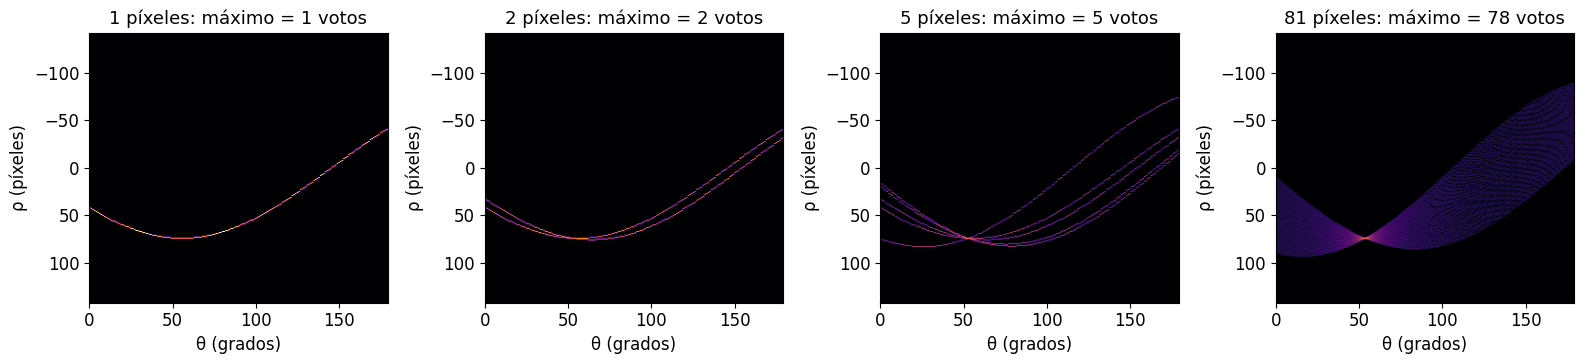

In [10]:
recta = np.zeros((100, 100), np.uint8)
cv2.line(recta, (10, 85), (90, 25), 255, 1)
filas, columnas = np.nonzero(recta)
orden = np.random.default_rng(1).permutation(len(filas))

fig, ax = plt.subplots(1, 4, figsize=(16, 3.8))
for a, n in zip(ax, [1, 2, 5, len(filas)]):
    parcial = np.zeros_like(recta)
    parcial[filas[orden[:n]], columnas[orden[:n]]] = 255
    A, thetas, rhos = hough_con_bucles(parcial)
    ver_acumulador(a, A, thetas, rhos, f"{n} píxeles: máximo = {A.max()} votos")
fig.tight_layout()
plt.show()

### 4.3 Lo mismo, sin un bucle

Para cada $\theta$ se calculan **todos** los $\rho$ de una vez con NumPy. `np.add.at` suma correctamente
aunque varios píxeles caigan en la misma celda.

In [11]:
def acumulador(bordes, dtheta=1.0, drho=1.0):
    M, N = bordes.shape
    D = int(np.ceil(np.hypot(M, N)))
    thetas = np.arange(0, 180, dtheta)
    rhos = np.arange(-D, D + drho, drho)
    A = np.zeros((len(rhos), len(thetas)), dtype=int)
    filas, columnas = np.nonzero(bordes)
    for j, t in enumerate(np.deg2rad(thetas)):
        rho = columnas * np.cos(t) + filas * np.sin(t)
        np.add.at(A[:, j], np.round((rho + D) / drho).astype(int), 1)
    return A, thetas, rhos


formas = cargar("formas_bordes.png")
A1, thetas, rhos = hough_con_bucles(formas)
A2, _, _ = acumulador(formas)
print("¿Ambas versiones dan el mismo acumulador?", np.array_equal(A1, A2))
print(f"Tamaño: {A2.shape[0]} valores de ρ × {A2.shape[1]} valores de θ = {A2.size} celdas")

¿Ambas versiones dan el mismo acumulador? True
Tamaño: 1001 valores de ρ × 180 valores de θ = 180180 celdas


### 4.4 De los votos a las rectas: umbral y supresión de no máximos

Por el redondeo, una recta llena de votos **varias celdas vecinas**. Si solo usamos un umbral,
detectamos muchas veces la misma recta. Por eso nos quedamos con las celdas que además son el **máximo de
su vecindario**: es la misma supresión de no máximos que usa Canny.

ρ =    245   θ =    57°   votos = 232
ρ =    325   θ =    28°   votos = 121
ρ =   -234   θ =   155°   votos = 111
ρ =    289   θ =    82°   votos = 97
ρ =    113   θ =   110°   votos = 90
ρ =     23   θ =   110°   votos = 88
ρ =    236   θ =    19°   votos = 57
ρ =     86   θ =    19°   votos = 54


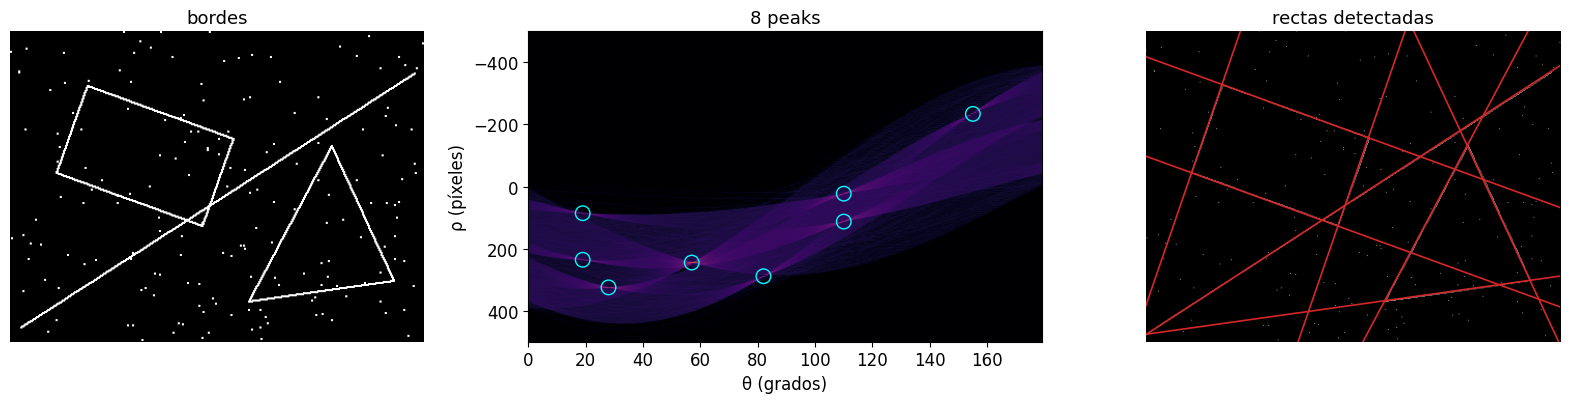

In [12]:
def peaks(A, thetas, rhos, umbral, vecindad=21):
    es_maximo = A == ndimage.maximum_filter(A, size=vecindad)
    filas, columnas = np.nonzero(es_maximo & (A >= umbral))
    orden = np.argsort(-A[filas, columnas])                    # primero los de más votos
    return [(rhos[filas[k]], thetas[columnas[k]], A[filas[k], columnas[k]]) for k in orden]


def dibujar_recta(ax, rho, theta_grados, forma, **estilo):
    # Dibuja x cos θ + y sin θ = ρ despejando la variable que esté mejor condicionada
    M, N = forma
    t = np.deg2rad(theta_grados)
    c, s = np.cos(t), np.sin(t)
    if abs(s) > abs(c):
        x = np.array([0, N - 1])
        y = (rho - x * c) / s
    else:
        y = np.array([0, M - 1])
        x = (rho - y * s) / c
    ax.plot(x, y, **estilo)
    ax.set_xlim(0, N - 1)
    ax.set_ylim(M - 1, 0)


lista = peaks(A2, thetas, rhos, umbral=40)
for rho, th, votos in lista:
    print(f"ρ = {rho:6.0f}   θ = {th:5.0f}°   votos = {votos}")

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2), gridspec_kw={"width_ratios": [1, 1.2, 1]})
ax[0].imshow(cv2.dilate(formas, np.ones((2, 2), np.uint8)))
ax[0].set_title("bordes")
ver_acumulador(ax[1], A2, thetas, rhos, f"{len(lista)} peaks")
ax[1].scatter([p[1] for p in lista], [p[0] for p in lista], s=110, facecolors="none", edgecolors="cyan")
ax[2].imshow(formas // 2, vmin=0, vmax=255)
for rho, th, _ in lista:
    dibujar_recta(ax[2], rho, th, formas.shape, color="tab:red", lw=1.2)
ax[2].set_title("rectas detectadas")
ax[0].axis("off")
ax[2].axis("off")
fig.tight_layout()
plt.show()

La imagen tiene **8 rectas**: los 4 lados del rectángulo, los 3 del triángulo y la diagonal. Con umbral 40
aparecen exactamente esas.

### 4.5 Explora: resolución, umbral y vecindad

- **$\Delta\theta$ y $\Delta\rho$ muy finos:** los votos de una recta se reparten en muchas celdas, baja
  el máximo y el cálculo se hace más lento.
- **Muy gruesos:** rectas distintas caen en la misma celda y la recta recuperada es imprecisa.
- **Sin supresión** (`vecindad = 1`): la misma recta aparece muchas veces.

In [13]:
@interact(imagen=widgets.Dropdown(options=["formas_bordes.png", "bordes de camera"], description="imagen"),
          dtheta=widgets.FloatLogSlider(value=1, base=2, min=-2, max=4, step=1, description="Δθ", continuous_update=False),
          drho=widgets.FloatLogSlider(value=1, base=2, min=-2, max=4, step=1, description="Δρ", continuous_update=False),
          umbral=widgets.IntSlider(value=40, min=5, max=300, description="umbral", continuous_update=False),
          vecindad=widgets.IntSlider(value=21, min=1, max=61, step=2, description="vecindad", continuous_update=False))
def explorar_acumulador(imagen, dtheta, drho, umbral, vecindad):
    im = cargar(imagen) if imagen.endswith(".png") else cv2.Canny(cargar("camera"), 100, 200)
    t0 = time.perf_counter()
    A, th, rh = acumulador(im, dtheta, drho)
    ms = 1000 * (time.perf_counter() - t0)
    tam = (max(1, int(vecindad / drho) | 1), max(1, int(vecindad / dtheta) | 1))    # vecindad medida en celdas
    lista = peaks(A, th, rh, umbral, tam)
    fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
    ver_acumulador(ax[0], A, th, rh, f"{A.shape[0]} × {A.shape[1]} celdas, {ms:.0f} ms, máximo = {A.max()} votos")
    ax[1].imshow(im // 2, vmin=0, vmax=255)
    for rho, t, _ in lista[:200]:
        dibujar_recta(ax[1], rho, t, im.shape, color="tab:red", lw=0.8)
    ax[1].set_title(f"{len(lista)} rectas")
    ax[1].axis("off")
    plt.show()

interactive(children=(Dropdown(description='imagen', options=('formas_bordes.png', 'bordes de camera'), value=…

---
## 5. Ejercicios a mano: comprueba tus cálculos

Los ejercicios de las láminas se hacen **con lápiz y papel**. Estas funciones sirven para comprobarlos.
Usan $\Delta\rho = 1$ y redondean $\rho$ al entero más cercano.

In [14]:
def tabla_rho(puntos, angulos):
    # Imprime ρ exacto y redondeado para cada punto y ángulo
    print("punto     " + "".join(f"{a:>14}°" for a in angulos))
    for x, y in puntos:
        fila = "".join(f"{rho_de(x, y, a):9.2f} → {int(np.round(rho_de(x, y, a))):3d}" + " " for a in angulos)
        print(f"({x}, {y})   " + fila)


def votar(puntos, angulos):
    # Imprime el acumulador, con una fila por valor entero de ρ
    votos = {}
    for x, y in puntos:
        for a in angulos:
            clave = (int(np.round(rho_de(x, y, a))), a)
            votos[clave] = votos.get(clave, 0) + 1
    lista = sorted({r for r, _ in votos})
    print("  ρ \\ θ " + "".join(f"{a:>6}°" for a in angulos))
    for r in range(lista[0], lista[-1] + 1):
        print(f"{r:6d}  " + "".join(f"{votos.get((r, a), '·'):>7}" for a in angulos))
    (r, a), v = max(votos.items(), key=lambda par: par[1])
    print(f"\nPeak: ρ = {r}, θ = {a}°, con {v} votos")


ANGULOS = [0, 45, 90, 135]

**Ejercicio 1.** Para el punto $P = (3, 4)$, calcula $\rho$ en $\theta = 0°, 45°, 90°, 135°$. ¿Cuál es el
mayor $\rho$ posible y en qué ángulo se alcanza?

In [15]:
tabla_rho([(3, 4)], ANGULOS)
print(f"\nMáximo: ρ = {np.hypot(3, 4):.2f} en θ = {np.degrees(np.arctan2(4, 3)):.2f}°")

punto                  0°            45°            90°           135°
(3, 4)        3.00 →   3      4.95 →   5      4.00 →   4      0.71 →   1 

Máximo: ρ = 5.00 en θ = 53.13°


**Ejercicio 2.** Haz votar los puntos $(1, 3)$, $(2, 2)$, $(3, 1)$ y $(4, 4)$. ¿Qué recta recibe más votos?

In [16]:
pts = [(1, 3), (2, 2), (3, 1), (4, 4)]
tabla_rho(pts, ANGULOS)
print()
votar(pts, ANGULOS)

punto                  0°            45°            90°           135°
(1, 3)        1.00 →   1      2.83 →   3      3.00 →   3      1.41 →   1 
(2, 2)        2.00 →   2      2.83 →   3      2.00 →   2      0.00 →   0 
(3, 1)        3.00 →   3      2.83 →   3      1.00 →   1     -1.41 →  -1 
(4, 4)        4.00 →   4      5.66 →   6      4.00 →   4      0.00 →   0 

  ρ \ θ      0°    45°    90°   135°
    -1        ·      ·      ·      1
     0        ·      ·      ·      2
     1        1      ·      1      1
     2        1      ·      1      ·
     3        1      3      1      ·
     4        1      ·      1      ·
     5        ·      ·      ·      ·
     6        ·      1      ·      ·

Peak: ρ = 3, θ = 45°, con 3 votos


El peak está en $\rho = 3$, $\theta = 45°$. Ojo: el valor exacto es $4/\sqrt{2} = 2.83$. **Redondear a una
celda introduce error**: con $\rho = 3$ la recta sería $x + y = 4.24$, no $x + y = 4$.

**Ejercicio 3.** Encuentra la recta que pasa por $A = (4, 3)$ y $B = (1, 7)$ igualando sus sinusoides.
¿Están en ella $(2, 5)$ y $(5, 2)$?

In [17]:
t = np.arctan2(3, 4)                 # de 4 cos θ + 3 sin θ = cos θ + 7 sin θ sale tan θ = 3/4
print(f"θ = {np.degrees(t):.2f}°")
print(f"ρ con A = {rho_de(4, 3, np.degrees(t)):.4f}   ρ con B = {rho_de(1, 7, np.degrees(t)):.4f}")
for p in [(2, 5), (5, 2)]:
    print(f"{p}: 4x + 3y = {4 * p[0] + 3 * p[1]}  → {'está' if 4 * p[0] + 3 * p[1] == 25 else 'no está'} en la recta")

θ = 36.87°
ρ con A = 5.0000   ρ con B = 5.0000
(2, 5): 4x + 3y = 23  → no está en la recta
(5, 2): 4x + 3y = 26  → no está en la recta


### 5.1 Ejercicios propuestos

Haz primero los dos ejercicios propuestos a mano (están en las láminas). Luego escribe aquí tus puntos para
comprobar el primero.

In [18]:
mis_puntos = [(0, 0)]   # escribe aquí tus puntos

tabla_rho(mis_puntos, ANGULOS)
print()
votar(mis_puntos, ANGULOS)

punto                  0°            45°            90°           135°
(0, 0)        0.00 →   0      0.00 →   0      0.00 →   0      0.00 →   0 

  ρ \ θ      0°    45°    90°   135°
     0        1      1      1      1

Peak: ρ = 0, θ = 0°, con 1 votos


---
## 6. Transición: de nuestro código a OpenCV

Ya sabemos qué ocurre por dentro. Desde aquí usaremos `cv2`, por tres razones: es **más rápido** (está
escrito en C++), ya está **probado** y resuelve casos que no programamos, como los segmentos.

| En nuestro código | En `cv2.HoughLines(bordes, rho, theta, threshold)` |
|---|---|
| `bordes` | imagen binaria `uint8` de **un canal** |
| `drho`, `dtheta` en grados | `rho` en píxeles y `theta` en **radianes** |
| `umbral` | `threshold`: votos mínimos |
| `peaks` entrega $(\rho, \theta, \text{votos})$ | entrega $(\rho, \theta)$ ordenados por votos, con $\theta$ en radianes |
| `vecindad` | no hay parámetro: su supresión es **muy local** y conviene agrupar las rectas vecinas |

### 6.1 ¿Dan lo mismo?

In [19]:
lineas = cv2.HoughLines(formas, 1, np.pi / 180, 40)
print("Forma de la salida:", lineas.shape, "  (n rectas, 1, 2 valores)")


def agrupar(lineas, drho=10, dtheta=np.deg2rad(10)):
    # Conserva la primera recta (la de más votos) de cada grupo de rectas parecidas
    grupo = []
    for rho, th in lineas[:, 0]:
        if not any(abs(rho - r) < drho and abs(th - t) < dtheta for r, t in grupo):
            grupo.append((rho, th))
    return grupo


grupo = agrupar(lineas)
print(f"Rectas crudas: {len(lineas)}   tras agrupar: {len(grupo)}")

nuestras = sorted((round(float(th)), round(float(rho))) for rho, th, _ in lista)
de_opencv = sorted((round(float(np.degrees(th))), round(float(rho))) for rho, th in grupo)
print("\n(θ, ρ) nuestro :", nuestras)
print("(θ, ρ) OpenCV  :", de_opencv)

Forma de la salida: (24, 1, 2)   (n rectas, 1, 2 valores)
Rectas crudas: 24   tras agrupar: 8

(θ, ρ) nuestro : [(19, 86), (19, 236), (28, 325), (57, 245), (82, 289), (110, 23), (110, 113), (155, -234)]
(θ, ρ) OpenCV  : [(19, 86), (19, 236), (28, 325), (57, 245), (82, 289), (110, 23), (110, 113), (155, -234)]


Encuentran las mismas 8 rectas: OpenCV hace lo mismo que programamos, más la parte de agrupar que aquí
hicimos aparte.

### 6.2 ¿Cuánto más rápido?

In [20]:
t0 = time.perf_counter(); hough_con_bucles(formas); t_bucles = time.perf_counter() - t0
t0 = time.perf_counter(); acumulador(formas); t_numpy = time.perf_counter() - t0
t0 = time.perf_counter(); cv2.HoughLines(formas, 1, np.pi / 180, 40); t_cv = time.perf_counter() - t0

print(f"Dos bucles:      {1000 * t_bucles:8.2f} ms")
print(f"NumPy:           {1000 * t_numpy:8.2f} ms")
print(f"cv2.HoughLines:  {1000 * t_cv:8.2f} ms")

Dos bucles:        280.13 ms
NumPy:               1.46 ms
cv2.HoughLines:      0.31 ms


### 6.3 De rectas infinitas a segmentos: `HoughLinesP`

`HoughLines` entrega rectas **infinitas**: no dice dónde empieza ni termina el objeto. `cv2.HoughLinesP`
(transformada de Hough **probabilística progresiva**) vota con píxeles tomados al azar, se detiene antes y
entrega **segmentos** `(x1, y1, x2, y2)`.

- `minLineLength`: largo mínimo; descarta segmentos cortos.
- `maxLineGap`: mayor hueco que se puede saltar y seguir considerando el mismo segmento.

In [21]:
segmentos = np.zeros((300, 400), np.uint8)
cv2.line(segmentos, (30, 60), (170, 60), 255, 1)
cv2.line(segmentos, (230, 60), (370, 60), 255, 1)      # misma recta, con un hueco de 60 píxeles
cv2.line(segmentos, (60, 260), (160, 120), 255, 1)
cv2.line(segmentos, (250, 120), (350, 260), 255, 1)


@interact(umbral=widgets.IntSlider(value=50, min=5, max=150, description="threshold", continuous_update=False),
          largo=widgets.IntSlider(value=40, min=0, max=200, description="minLineLength", continuous_update=False),
          hueco=widgets.IntSlider(value=5, min=0, max=120, description="maxLineGap", continuous_update=False))
def explorar_segmentos(umbral, largo, hueco):
    salida = cv2.cvtColor(segmentos // 2, cv2.COLOR_GRAY2RGB)
    s = cv2.HoughLinesP(segmentos, 1, np.pi / 180, umbral, minLineLength=largo, maxLineGap=hueco)
    n = 0 if s is None else len(s)
    for k in range(n):
        x1, y1, x2, y2 = s[k, 0]
        cv2.line(salida, (x1, y1), (x2, y2), (60, 255, 130), 2, cv2.LINE_AA)
    plt.figure(figsize=(7, 5))
    plt.imshow(salida)
    plt.title(f"{n} segmentos")
    plt.axis("off")
    plt.show()

interactive(children=(IntSlider(value=50, continuous_update=False, description='threshold', max=150, min=5), I…

---
## 7. Aplicación con OpenCV: rectas en una carretera

Ahora solo usamos la librería. El esquema es casi siempre el mismo:

$$\text{imagen} \to \text{gris} \to \text{suavizado} \to \text{Canny} \to \text{región de interés} \to \text{Hough} \to \text{filtrar por ángulo}$$

Foto: Dietmar Rabich, CC BY-SA 4.0 (Wikimedia Commons).

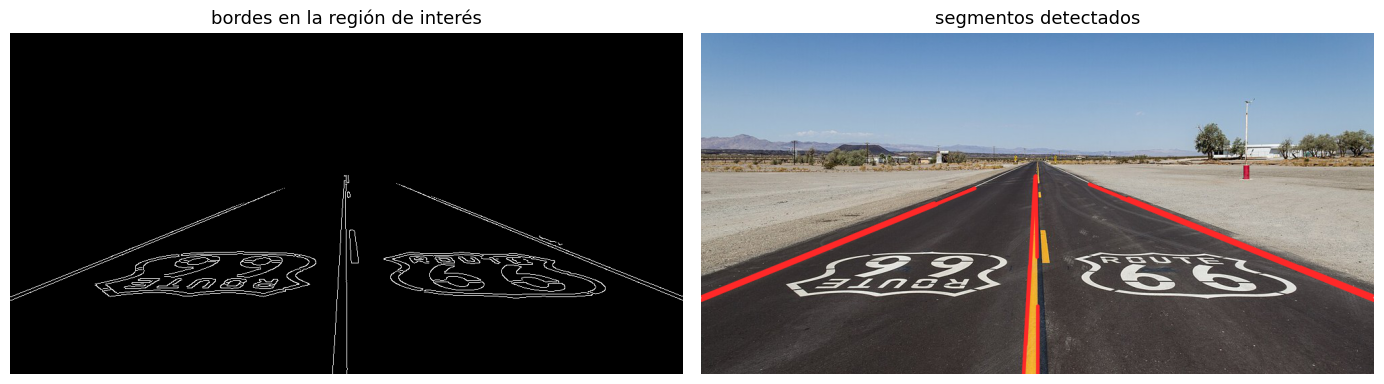

In [22]:
def rectas_carretera(canny_bajo=70, canny_alto=180, umbral=60, largo=90, hueco=20, usar_roi=True):
    gris = cv2.cvtColor(carretera, cv2.COLOR_RGB2GRAY)
    bordes = cv2.Canny(cv2.GaussianBlur(gris, (5, 5), 1.2), canny_bajo, canny_alto)
    M, N = gris.shape
    if usar_roi:                                 # solo la calzada, para no detectar el horizonte
        roi = np.zeros_like(bordes)
        vertices = [[0, M - 1], [N - 1, M - 1], [N - 1, int(.75 * M)], [int(.54 * N), int(.42 * M)],
                    [int(.46 * N), int(.42 * M)], [0, int(.75 * M)]]
        cv2.fillPoly(roi, [np.array(vertices)], 255)
        bordes = cv2.bitwise_and(bordes, roi)
    s = cv2.HoughLinesP(bordes, 1, np.pi / 180, umbral, minLineLength=largo, maxLineGap=hueco)
    salida = carretera.copy()
    if s is not None:
        for x1, y1, x2, y2 in s[:, 0]:
            if abs(y2 - y1) > 0.15 * abs(x2 - x1):       # se descartan los trazos casi horizontales
                cv2.line(salida, (x1, y1), (x2, y2), (255, 40, 40), 3, cv2.LINE_AA)
    return bordes, salida


bordes_c, salida_c = rectas_carretera()
ver([bordes_c, salida_c], ["bordes en la región de interés", "segmentos detectados"], figsize=(14, 4))

### 7.1 Explora el proceso completo

In [23]:
@interact(canny_alto=widgets.IntSlider(value=180, min=50, max=400, description="Canny alto", continuous_update=False),
          umbral=widgets.IntSlider(value=60, min=10, max=200, description="threshold", continuous_update=False),
          largo=widgets.IntSlider(value=90, min=10, max=300, description="minLineLength", continuous_update=False),
          hueco=widgets.IntSlider(value=20, min=0, max=100, description="maxLineGap", continuous_update=False),
          usar_roi=widgets.Checkbox(value=True, description="región de interés"))
def explorar_carretera(canny_alto, umbral, largo, hueco, usar_roi):
    b, s = rectas_carretera(canny_alto // 2, canny_alto, umbral, largo, hueco, usar_roi)
    ver([b, s], ["bordes", "resultado"], figsize=(14, 4))

interactive(children=(IntSlider(value=180, continuous_update=False, description='Canny alto', max=400, min=50)…

---
## 8. Extensiones: círculos, elipses y formas arbitrarias

La idea no depende de la recta: **cualquier forma con parámetros puede votar**. El costo es que el
acumulador tiene una dimensión por cada parámetro.

| Forma | Parámetros | Acumulador |
|---|---|---|
| Recta | $\rho, \theta$ | 2D |
| Círculo | $a, b, r$ | 3D |
| Elipse | $x_0, y_0, a, b, \phi$ | 5D |
| Forma arbitraria (generalizada) | posición, y opcionalmente escala y rotación | 2D a 4D |

### 8.1 Círculos, a mano: con $r$ conocido

Un círculo es $(x-a)^2 + (y-b)^2 = r^2$. Si conocemos $r$, cada píxel de borde vota por un **círculo de
posibles centros** de radio $r$. El centro real recibe votos de todos.

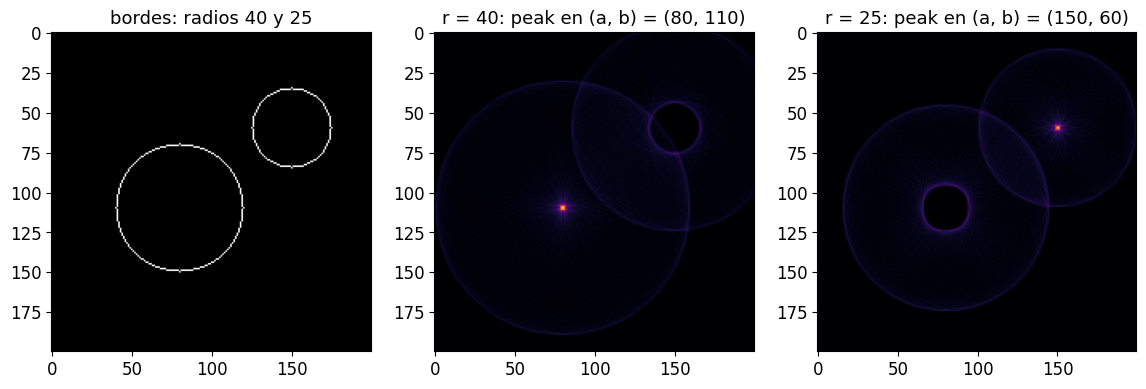

In [24]:
def hough_circulo_r(bordes, r):
    M, N = bordes.shape
    A = np.zeros((M, N), dtype=int)
    filas, columnas = np.nonzero(bordes)
    t = np.deg2rad(np.arange(360))
    for y, x in zip(filas, columnas):
        a = np.round(x - r * np.cos(t)).astype(int)
        b = np.round(y - r * np.sin(t)).astype(int)
        dentro = (a >= 0) & (a < N) & (b >= 0) & (b < M)
        np.add.at(A, (b[dentro], a[dentro]), 1)
    return A


disco = np.zeros((200, 200), np.uint8)
cv2.circle(disco, (80, 110), 40, 255, 1)
cv2.circle(disco, (150, 60), 25, 255, 1)

fig, ax = plt.subplots(1, 3, figsize=(14, 4.2))
ax[0].imshow(disco)
ax[0].set_title("bordes: radios 40 y 25")
for a, r in zip(ax[1:], [40, 25]):
    A = hough_circulo_r(disco, r)
    b0, a0 = np.unravel_index(A.argmax(), A.shape)
    a.imshow(A, cmap="inferno")
    a.set_title(f"r = {r}: peak en (a, b) = ({a0}, {b0})")
plt.show()

### 8.2 Círculos con OpenCV: `cv2.HoughCircles`

Barrer todos los radios en 3D es caro. `HOUGH_GRADIENT` usa la **dirección del gradiente** (la misma de
Canny): en un círculo el gradiente apunta al centro, así que cada píxel vota solo a lo largo de esa
dirección y luego se estima el radio.

| Parámetro | Significado |
|---|---|
| `dp` | $\Delta$ del acumulador: 1 = misma resolución de la imagen, 2 = la mitad |
| `minDist` | distancia mínima entre centros |
| `param1` | umbral **alto** de Canny (el bajo es la mitad). Recibe la imagen en gris, no los bordes |
| `param2` | votos mínimos: bajo = muchos círculos falsos, alto = se pierden círculos |
| `minRadius`, `maxRadius` | rango de radios buscado |

Círculos encontrados: 24


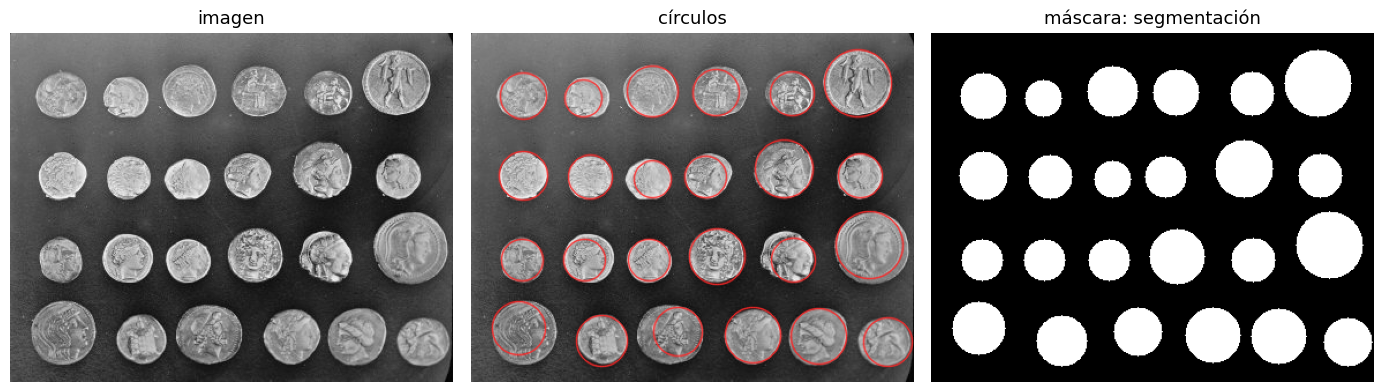

In [25]:
monedas = cargar("coins")
suave = cv2.medianBlur(monedas, 3)
c = cv2.HoughCircles(suave, cv2.HOUGH_GRADIENT, dp=1.2, minDist=30, param1=100, param2=28, minRadius=12, maxRadius=40)
print(f"Círculos encontrados: {c.shape[1]}")


def dibujar_circulos(gris, circulos):
    salida = cv2.cvtColor(gris, cv2.COLOR_GRAY2RGB)
    for x, y, r in np.round(circulos).astype(int):
        cv2.circle(salida, (x, y), r, (255, 40, 40), 1, cv2.LINE_AA)
    return salida


mascara = np.zeros_like(monedas)
for x, y, r in np.round(c[0]).astype(int):
    cv2.circle(mascara, (x, y), r, 255, -1)
ver([monedas, dibujar_circulos(monedas, c[0]), mascara], ["imagen", "círculos", "máscara: segmentación"], figsize=(14, 4))

### 8.3 Explora `HoughCircles`

In [26]:
@interact(imagen=widgets.Dropdown(options=["coins", "gotas_simuladas.png"], description="imagen"),
          mediana=widgets.IntSlider(value=3, min=1, max=11, step=2, description="mediana", continuous_update=False),
          dp=widgets.FloatSlider(value=1.2, min=1, max=3, step=0.1, description="dp", continuous_update=False),
          minDist=widgets.IntSlider(value=30, min=5, max=150, description="minDist", continuous_update=False),
          param1=widgets.IntSlider(value=100, min=20, max=300, description="param1", continuous_update=False),
          param2=widgets.IntSlider(value=28, min=5, max=100, description="param2", continuous_update=False),
          rmin=widgets.IntSlider(value=12, min=0, max=100, description="minRadius", continuous_update=False),
          rmax=widgets.IntSlider(value=40, min=1, max=150, description="maxRadius", continuous_update=False))
def explorar_circulos(imagen, mediana, dp, minDist, param1, param2, rmin, rmax):
    g = cargar(imagen)
    k = cv2.HoughCircles(cv2.medianBlur(g, mediana), cv2.HOUGH_GRADIENT, dp=dp, minDist=minDist,
                         param1=param1, param2=param2, minRadius=rmin, maxRadius=rmax)
    n = 0 if k is None else k.shape[1]
    ver([g, dibujar_circulos(g, k[0]) if n else g], ["imagen", f"{n} círculos"], figsize=(14, 4))

interactive(children=(Dropdown(description='imagen', options=('coins', 'gotas_simuladas.png'), value='coins'),…

### 8.4 Elipses

Con 5 parámetros, un acumulador completo es impracticable. `skimage.transform.hough_ellipse` (basada en
Xie y Ji, 2002) toma **pares de píxeles** como posibles extremos del eje mayor: con eso quedan fijos el
centro, $a$ y la orientación, y solo se vota por $b$ en un acumulador 1D. Por eso exige imágenes pequeñas
o pocos bordes.

1.7 s para 484 píxeles de borde
Centro = (150, 110)   a = 110   b = 56


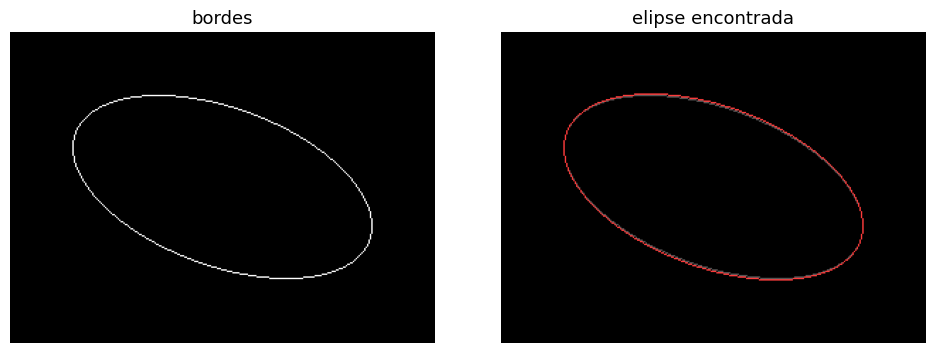

In [27]:
borde_elipse = np.zeros((220, 300), np.uint8)
yy, xx = ellipse_perimeter(110, 150, 55, 110, orientation=np.deg2rad(20))
dentro = (yy >= 0) & (yy < 220) & (xx >= 0) & (xx < 300)
borde_elipse[yy[dentro], xx[dentro]] = 255

t0 = time.perf_counter()
resultado = hough_ellipse(borde_elipse, accuracy=10, threshold=60, min_size=60, max_size=130)
resultado.sort(order="accumulator")
_, yc, xc, a, b, orient = list(resultado[-1])
print(f"{time.perf_counter() - t0:.1f} s para {np.count_nonzero(borde_elipse)} píxeles de borde")
print(f"Centro = ({xc:.0f}, {yc:.0f})   a = {a:.0f}   b = {b:.0f}")

yy2, xx2 = ellipse_perimeter(int(round(yc)), int(round(xc)), int(round(a)), int(round(b)), orient)
salida = cv2.cvtColor(borde_elipse // 3, cv2.COLOR_GRAY2RGB)
dentro = (yy2 >= 0) & (yy2 < 220) & (xx2 >= 0) & (xx2 < 300)
salida[yy2[dentro], xx2[dentro]] = (255, 60, 60)
ver([borde_elipse, salida], ["bordes", "elipse encontrada"], figsize=(10, 3.6))

### 8.5 Formas arbitrarias: transformada generalizada

Ballard (1981) elimina las fórmulas: guarda la forma en una **tabla R**. Para cada píxel de borde de una
plantilla se anota el vector $\mathbf{r}$ hacia un punto de referencia, indexado por la orientación
$\varphi$ del borde. Al detectar, cada píxel busca en la tabla los vectores de su orientación y vota por
las posibles posiciones de la referencia. Aquí basta con entender la idea; OpenCV la ofrece en
`cv2.createGeneralizedHoughBallard`.

---
## 9. Un adelanto: RANSAC

RANSAC (*Random Sample Consensus*, Fischler y Bolles, 1981) también encuentra modelos entre datos
ruidosos, pero **sin acumulador**: propone y comprueba.

1. Elegir al azar los puntos mínimos del modelo (**2** para una recta).
2. Construir el modelo y contar cuántos puntos están cerca de él (los *inliers*).
3. Repetir y quedarse con el modelo de mayor acuerdo.

Lo veremos con detalle en la clase de correspondencia de imágenes, para estimar homografías, donde un
acumulador tendría demasiadas dimensiones.

Recta real:           y = 0.60 x + 1.50
RANSAC:               y = 0.60 x + 1.53   (40 inliers)
Mínimos cuadrados:    y = 0.20 x + 3.06


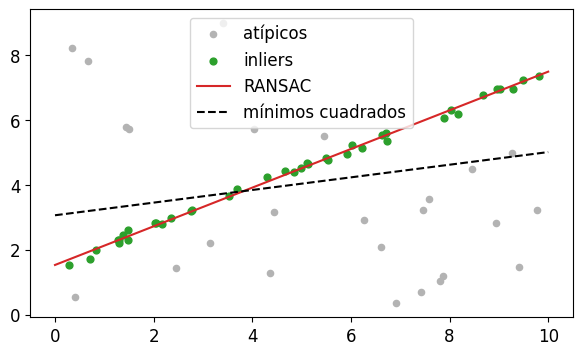

In [28]:
rng = np.random.default_rng(11)
x = rng.uniform(0, 10, 40)
y = 0.6 * x + 1.5 + rng.normal(0, 0.12, 40)
X = np.r_[x, rng.uniform(0, 10, 25)]
Y = np.r_[y, rng.uniform(0, 9, 25)]
puntos_xy = np.column_stack([X, Y])

modelo, inliers = ransac(puntos_xy, LineModelND, min_samples=2, residual_threshold=0.4, max_trials=100, rng=0)
m_all, b_all = np.polyfit(X, Y, 1)
xx = np.array([0, 10])
origen, direccion = modelo.params
pendiente = direccion[1] / direccion[0]
yy = origen[1] + pendiente * (xx - origen[0])

print(f"Recta real:           y = 0.60 x + 1.50")
print(f"RANSAC:               y = {pendiente:.2f} x + {yy[0]:.2f}   ({inliers.sum()} inliers)")
print(f"Mínimos cuadrados:    y = {m_all:.2f} x + {b_all:.2f}")

plt.figure(figsize=(7, 4))
plt.scatter(X[~inliers], Y[~inliers], color="0.7", s=20, label="atípicos")
plt.scatter(X[inliers], Y[inliers], color="tab:green", s=24, label="inliers")
plt.plot(xx, yy, "tab:red", label="RANSAC")
plt.plot(xx, m_all * xx + b_all, "k--", label="mínimos cuadrados")
plt.legend()
plt.show()

---
## 10. Actividad final

Trabaja con lo visto en la clase, usando directamente OpenCV.

### Parte 1: enderezar un documento

La imagen `documento_inclinado.png` es una página fotografiada con el papel girado.

**Pasos sugeridos**

1. Carga la imagen y obtén sus bordes con Canny.
2. Aplica `cv2.HoughLines`. Usa una resolución angular fina: $\Delta\theta = 0.5°$.
3. Observa los valores de $\theta$. ¿Por qué aparecen dos grupos? ¿Cuál corresponde al texto?
4. Estima la inclinación del documento (recuerda: una línea horizontal tiene $\theta = 90°$).
5. Endereza la imagen con `cv2.getRotationMatrix2D` y `cv2.warpAffine`.
6. Comprueba tu resultado volviendo a medir el ángulo.

### Parte 2: contar monedas

Usa `cargar("coins")`.

1. Detecta las monedas con `cv2.HoughCircles`.
2. Ajusta los parámetros hasta contar bien las monedas. ¿Cuántas son?
3. Construye una máscara con los círculos y muestra solo las monedas sobre fondo negro.
4. Haz un histograma de los radios. ¿Qué harías para separar monedas grandes y chicas?

**Preguntas para discutir**

- ¿Qué ocurre con el conteo al mover `param2`? Grafica el número de círculos en función de `param2`.
- ¿Por qué `HoughCircles` recibe la imagen en gris y `HoughLines` los bordes?
- ¿Qué pasaría en la Parte 1 si el documento no tuviera sus bordes visibles? ¿Y si el texto estuviera en dos
  columnas?
- ¿Sirve este método de la Parte 1 si la foto tiene perspectiva?

In [29]:
# Parte 1.1 Cargar la imagen y obtener los bordes

In [30]:
# Parte 1.2 Aplicar HoughLines y observar los valores de θ

In [31]:
# Parte 1.3 Estimar la inclinación y enderezar

In [32]:
# Parte 1.4 Comprobar volviendo a medir

In [33]:
# Parte 2.1 Detectar las monedas

In [34]:
# Parte 2.2 Máscara y monedas sobre fondo negro

In [35]:
# Parte 2.3 Histograma de radios

In [36]:
# Parte 2.4 Número de círculos en función de param2